#KMEANS


import modul

In [ ]:
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import plotly.graph_objs as go

memanggil dataset yang dibutuhkan

In [ ]:
data = pd.read_excel("dataset_project2_new.xlsx")
data.head(5)

,nama_kabupaten_kota,indeks_pembangunan_literasi_masyarakat,indeks_pendidikan,indeks_masyarakat_digital_indonesia,Tahun
0,KABUPATEN BOGOR,65.70,62.52,39.95,2022
1,KABUPATEN SUKABUMI,50.29,57.73,38.31,2022
2,KABUPATEN CIANJUR,52.04,57.36,43.20,2022
3,KABUPATEN BANDUNG,82.09,65.57,44.15,2022
4,KABUPATEN GARUT,51.10,59.85,43.54,2022


periksa missing values

In [ ]:
print("\nMissing Values:")
print(data.isnull().sum())


Missing Values:
nama_kabupaten_kota                       0
indeks_pembangunan_literasi_masyarakat    0
indeks_pendidikan                         0
indeks_masyarakat_digital_indonesia       0
Tahun                                     0
dtype: int64


memilih fitur/variabel yang digunakan untuk clustering

In [ ]:
X = data[['indeks_pembangunan_literasi_masyarakat', 'indeks_pendidikan', 'indeks_masyarakat_digital_indonesia']]

standarisasi data

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled

array([[-0.41306285, -0.36769016, -0.67113083],
       [-1.31855843, -1.09203698, -0.99609172],
       [-1.21572798, -1.14798862, -0.02715346],
       [ 0.55001778,  0.09353276,  0.16108608],
       [-1.27096262, -0.77144925,  0.04021648],
       [-1.05825049, -0.63686289,  0.07786439],
       [-0.46829749,  0.20846044,  0.06003117],
       [-1.25568496, -0.70793658,  0.03030913],
       [-0.06931534, -0.93325532, -1.66979112],
       [ 0.60290201, -0.9045234 , -1.89567857],
       [-1.41022443,  0.0300201 , -0.66716789],
       [-0.92662751, -1.22511114,  0.71391588],
       [-1.55124905, -1.24476982,  1.1320058 ],
       [ 0.04761757, -0.63837509,  1.28656037],
       [ 0.18041576, -0.68979011, -0.6473532 ],
       [-0.15393011,  0.48821861, -1.65393937],
       [ 0.02176306, -0.68374128,  0.79911904],
       [-0.43010333, -0.68676569,  0.5474725 ],
       [ 1.3285912 ,  1.17778468,  0.04814235],
       [ 1.41731919,  0.99783213,  0.65843475],
       [ 1.34680688,  1.69949586,  2.172

elbow method untuk menentukan nilai K

In [ ]:
inertia = []
K = range(1, 10)
for k in K:
    kmeans = KMeans(n_clusters=k, random_state=0)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

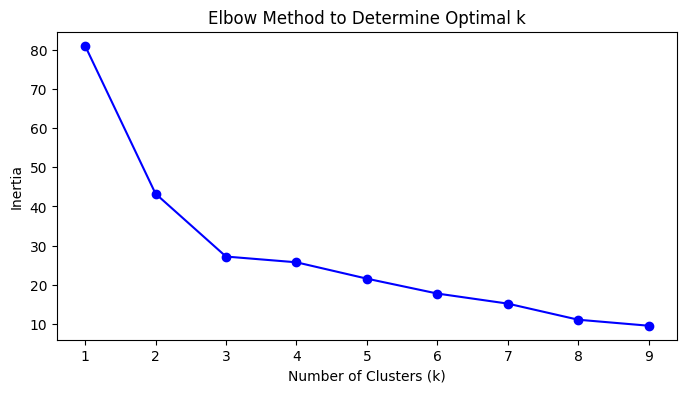

In [ ]:
plt.figure(figsize=(8, 4))
plt.plot(K, inertia, 'bo-')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method to Determine Optimal k')
plt.show()

Validasi nilai K dengan Slihoutte Score

In [ ]:
sil_scores = []
for k in range(2, 10):
    kmeans = KMeans(n_clusters=k, random_state=0)
    labels = kmeans.fit_predict(X_scaled)
    sil_scores.append(silhouette_score(X_scaled, labels))

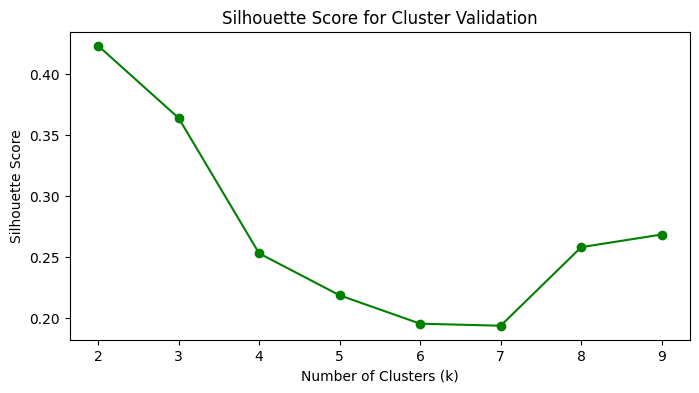

In [ ]:
plt.figure(figsize=(8, 4))
plt.plot(range(2, 10), sil_scores, 'go-')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score for Cluster Validation')
plt.show()

Clustering dengan nilai K=3

In [ ]:
kmeans = KMeans(n_clusters=3, random_state=0)
data['Cluster'] = kmeans.fit_predict(X_scaled)
centroids = kmeans.cluster_centers_
data.head(5)

,nama_kabupaten_kota,indeks_pembangunan_literasi_masyarakat,indeks_pendidikan,indeks_masyarakat_digital_indonesia,Tahun,Cluster
0,KABUPATEN BOGOR,65.70,62.52,39.95,2022,0
1,KABUPATEN SUKABUMI,50.29,57.73,38.31,2022,0
2,KABUPATEN CIANJUR,52.04,57.36,43.20,2022,2
3,KABUPATEN BANDUNG,82.09,65.57,44.15,2022,0
4,KABUPATEN GARUT,51.10,59.85,43.54,2022,2


Mapping cluster ke kategori (rendah, sedang, tinggi)

In [ ]:
# Mapping cluster ke kategori (rendah, sedang, tinggi)
centroids = kmeans.cluster_centers_
sorted_indices = centroids[:, 0].argsort()
cluster_map = {sorted_indices[0]: 'Rendah', sorted_indices[1]: 'Sedang', sorted_indices[2]: 'Tinggi'}
data['Kategori'] = data['Cluster'].map(cluster_map)

In [ ]:
remap_cluster = {0: 1, 1: 2, 2: 0}
data['Cluster'] = data['Cluster'].map(remap_cluster)

Analisis rentang per indeks

In [ ]:
cluster_ranges = {}
for cluster in data['Cluster'].unique():
    cluster_data = data[data['Cluster'] == cluster]
    cluster_ranges[cluster] = {
        'indeks_pembangunan_literasi_masyarakat': (cluster_data['indeks_pembangunan_literasi_masyarakat'].min(),
                                                   cluster_data['indeks_pembangunan_literasi_masyarakat'].max()),
        'indeks_pendidikan': (cluster_data['indeks_pendidikan'].min(),
                              cluster_data['indeks_pendidikan'].max()),
        'indeks_masyarakat_digital_indonesia': (cluster_data['indeks_masyarakat_digital_indonesia'].min(),
                                                cluster_data['indeks_masyarakat_digital_indonesia'].max())
    }

In [ ]:
# Tampilkan rentang tiap indeks per cluster
print("\nRanges per Index for Each Cluster:")
for cluster, ranges in cluster_ranges.items():
    print(f"Cluster {cluster}:")
    for index, value_range in ranges.items():
        print(f"  {index}: {value_range[0]:.2f} - {value_range[1]:.2f}")


Ranges per Index for Each Cluster:
Cluster 1:
  indeks_pembangunan_literasi_masyarakat: 48.73 - 92.62
  indeks_pendidikan: 57.73 - 70.93
  indeks_masyarakat_digital_indonesia: 33.77 - 44.15
Cluster 0:
  indeks_pembangunan_literasi_masyarakat: 46.33 - 73.54
  indeks_pendidikan: 56.72 - 60.74
  indeks_masyarakat_digital_indonesia: 43.20 - 49.83
Cluster 2:
  indeks_pembangunan_literasi_masyarakat: 79.68 - 98.92
  indeks_pendidikan: 69.18 - 77.33
  indeks_masyarakat_digital_indonesia: 43.58 - 54.30


In [ ]:
# 1. Inertia (SSE)
sse = kmeans.inertia_
print(f"Inertia (SSE): {sse}")

# 2. Silhouette Score
silhouette_avg = silhouette_score(X, labels)
print(f"Silhouette Score: {silhouette_avg}")

Inertia (SSE): 27.22206607924219
Silhouette Score: 0.1614919862217696


In [ ]:
data

,nama_kabupaten_kota,indeks_pembangunan_literasi_masyarakat,indeks_pendidikan,indeks_masyarakat_digital_indonesia,Tahun,Cluster,Kategori
0,KABUPATEN BOGOR,65.70,62.52,39.95,2022,1,Sedang
1,KABUPATEN SUKABUMI,50.29,57.73,38.31,2022,1,Sedang
2,KABUPATEN CIANJUR,52.04,57.36,43.20,2022,0,Rendah
3,KABUPATEN BANDUNG,82.09,65.57,44.15,2022,1,Sedang
4,KABUPATEN GARUT,51.10,59.85,43.54,2022,0,Rendah
5,KABUPATEN TASIKMALAYA,54.72,60.74,43.73,2022,0,Rendah
6,KABUPATEN CIAMIS,64.76,66.33,43.64,2022,1,Sedang
7,KABUPATEN KUNINGAN,51.36,60.27,43.49,2022,0,Rendah
8,KABUPATEN CIREBON,71.55,58.78,34.91,2022,1,Sedang
9,KABUPATEN MAJALENGKA,82.99,58.97,33.77,2022,1,Sedang


Simpan hasil clustering ke file excel baru

In [ ]:
data.to_excel("hasil_clustering.xlsx", index=False)


Visualisasi clustering dalam 3D menggunakan plotly

In [ ]:
import plotly.graph_objs as go

# Visualisasi hasil klasterisasi dalam 3D dengan Plotly
trace = go.Scatter3d(
    x=data['indeks_pembangunan_literasi_masyarakat'],
    y=data['indeks_pendidikan'],
    z=data['indeks_masyarakat_digital_indonesia'],
    mode='markers',  # Marker tanpa teks langsung terlihat
    marker=dict(color=data['Cluster'], colorscale='Viridis', size=5),
    name='Data Points',
    hovertext=data.apply(
        lambda row: f"Kabupaten/Kota: {row['nama_kabupaten_kota']}<br>Kluster: {row['Cluster']}", axis=1
    ),
    hoverinfo='x+y+z+text'  # Menampilkan nilai x, y, z, dan teks hovertext
)

# Menambahkan centroid ke plot Plotly dengan kategori: Rendah, Sedang, Tinggi
centroids = kmeans.cluster_centers_

# Denormalisasi centroid ke skala asli
centroids_data = go.Scatter3d(
    x=centroids[:, 0] * scaler.scale_[0] + scaler.mean_[0],
    y=centroids[:, 1] * scaler.scale_[1] + scaler.mean_[1],
    z=centroids[:, 2] * scaler.scale_[2] + scaler.mean_[2],
    mode='markers+text',  # Menambahkan teks untuk label centroid
    marker=dict(color='black', size=10, symbol='diamond'),
    name='Centroids',
    text=['Sedang', 'Tinggi', 'Rendah'],  # Menambahkan label kategori pada centroid
    textposition='top center'  # Posisi teks label
)

# Gabungan data dan centroid untuk plotly
data_plotly = [trace, centroids_data]
layout = go.Layout(
    title='3D KMeans Clustering with Centroids (Plotly)',
    scene=dict(
        xaxis=dict(title='Indeks Pembangunan Literasi Masyarakat'),
        yaxis=dict(title='Indeks Pendidikan'),
        zaxis=dict(title='Indeks Masyarakat Digital Indonesia')
    )
)

fig = go.Figure(data=data_plotly, layout=layout)
fig.show()


#K=5

import modul

In [ ]:
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import plotly.graph_objs as go

memanggil dataset yang dibutuhkan

In [ ]:
data = pd.read_excel("dataset_project2_new.xlsx")
data.head(5)

,nama_kabupaten_kota,indeks_pembangunan_literasi_masyarakat,indeks_pendidikan,indeks_masyarakat_digital_indonesia,Tahun
0,KABUPATEN BOGOR,65.70,62.52,39.95,2022
1,KABUPATEN SUKABUMI,50.29,57.73,38.31,2022
2,KABUPATEN CIANJUR,52.04,57.36,43.20,2022
3,KABUPATEN BANDUNG,82.09,65.57,44.15,2022
4,KABUPATEN GARUT,51.10,59.85,43.54,2022


periksa missing values

In [ ]:
print("\nMissing Values:")
print(data.isnull().sum())


Missing Values:
nama_kabupaten_kota                       0
indeks_pembangunan_literasi_masyarakat    0
indeks_pendidikan                         0
indeks_masyarakat_digital_indonesia       0
Tahun                                     0
dtype: int64


memilih fitur/variabel yang digunakan untuk clustering

In [ ]:
X = data[['indeks_pembangunan_literasi_masyarakat', 'indeks_pendidikan', 'indeks_masyarakat_digital_indonesia']]

standarisasi data

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled

array([[-0.41306285, -0.36769016, -0.67113083],
       [-1.31855843, -1.09203698, -0.99609172],
       [-1.21572798, -1.14798862, -0.02715346],
       [ 0.55001778,  0.09353276,  0.16108608],
       [-1.27096262, -0.77144925,  0.04021648],
       [-1.05825049, -0.63686289,  0.07786439],
       [-0.46829749,  0.20846044,  0.06003117],
       [-1.25568496, -0.70793658,  0.03030913],
       [-0.06931534, -0.93325532, -1.66979112],
       [ 0.60290201, -0.9045234 , -1.89567857],
       [-1.41022443,  0.0300201 , -0.66716789],
       [-0.92662751, -1.22511114,  0.71391588],
       [-1.55124905, -1.24476982,  1.1320058 ],
       [ 0.04761757, -0.63837509,  1.28656037],
       [ 0.18041576, -0.68979011, -0.6473532 ],
       [-0.15393011,  0.48821861, -1.65393937],
       [ 0.02176306, -0.68374128,  0.79911904],
       [-0.43010333, -0.68676569,  0.5474725 ],
       [ 1.3285912 ,  1.17778468,  0.04814235],
       [ 1.41731919,  0.99783213,  0.65843475],
       [ 1.34680688,  1.69949586,  2.172

elbow method untuk menentukan nilai K

In [ ]:
inertia = []
K = range(1, 10)
for k in K:
    kmeans = KMeans(n_clusters=k, random_state=0)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

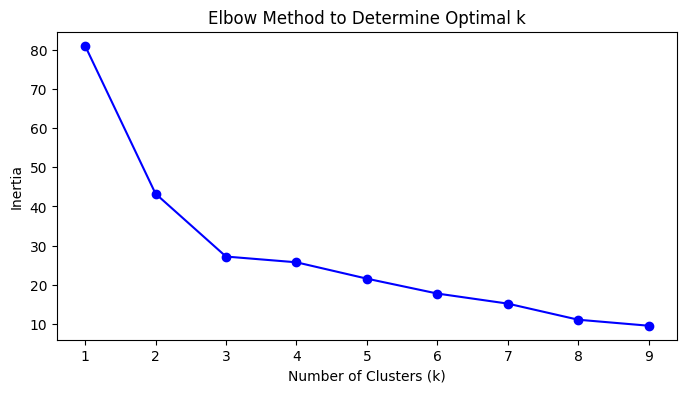

In [ ]:
plt.figure(figsize=(8, 4))
plt.plot(K, inertia, 'bo-')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method to Determine Optimal k')
plt.show()

Validasi nilai K dengan Slihoutte Score

In [ ]:
sil_scores = []
for k in range(2, 10):
    kmeans = KMeans(n_clusters=k, random_state=0)
    labels = kmeans.fit_predict(X_scaled)
    sil_scores.append(silhouette_score(X_scaled, labels))

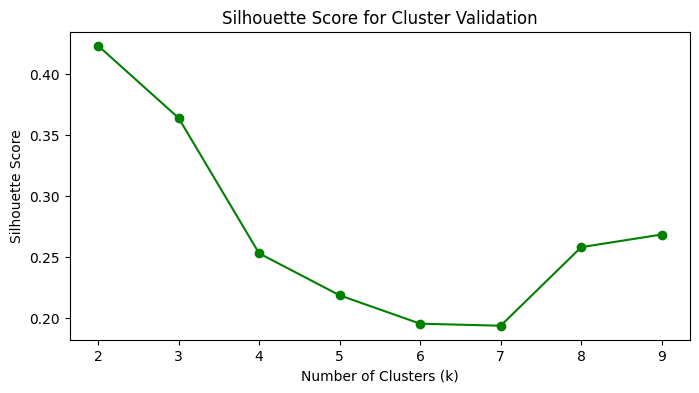

In [ ]:
plt.figure(figsize=(8, 4))
plt.plot(range(2, 10), sil_scores, 'go-')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score for Cluster Validation')
plt.show()

Clustering dengan nilai K=3

In [ ]:
kmeans = KMeans(n_clusters=5, random_state=0)
data['Cluster'] = kmeans.fit_predict(X_scaled)
centroids = kmeans.cluster_centers_
data.head(5)

,nama_kabupaten_kota,indeks_pembangunan_literasi_masyarakat,indeks_pendidikan,indeks_masyarakat_digital_indonesia,Tahun,Cluster
0,KABUPATEN BOGOR,65.70,62.52,39.95,2022,0
1,KABUPATEN SUKABUMI,50.29,57.73,38.31,2022,0
2,KABUPATEN CIANJUR,52.04,57.36,43.20,2022,2
3,KABUPATEN BANDUNG,82.09,65.57,44.15,2022,0
4,KABUPATEN GARUT,51.10,59.85,43.54,2022,2


Mapping cluster ke kategori (rendah, sedang, tinggi)

In [ ]:
# Mapping cluster ke kategori (rendah, sedang, tinggi)
centroids = kmeans.cluster_centers_
sorted_indices = centroids[:, 0].argsort()
cluster_map = {sorted_indices[0]: 'Sangat Rendah', sorted_indices[1]: 'Rendah', sorted_indices[2]: 'Sedang', sorted_indices[3]: 'Tinggi', sorted_indices[4]: 'Sangat Tinggi'}
data['Kategori'] = data['Cluster'].map(cluster_map)

In [ ]:
remap_cluster = {2: 0, 0: 1, 4: 2, 1: 3, 3: 4}
data['Cluster'] = data['Cluster'].map(remap_cluster)


Analisis rentang per indeks

In [ ]:
cluster_ranges = {}
for cluster in data['Cluster'].unique():
    cluster_data = data[data['Cluster'] == cluster]
    cluster_ranges[cluster] = {
        'indeks_pembangunan_literasi_masyarakat': (cluster_data['indeks_pembangunan_literasi_masyarakat'].min(),
                                                   cluster_data['indeks_pembangunan_literasi_masyarakat'].max()),
        'indeks_pendidikan': (cluster_data['indeks_pendidikan'].min(),
                              cluster_data['indeks_pendidikan'].max()),
        'indeks_masyarakat_digital_indonesia': (cluster_data['indeks_masyarakat_digital_indonesia'].min(),
                                                cluster_data['indeks_masyarakat_digital_indonesia'].max())
    }

In [ ]:
# Tampilkan rentang tiap indeks per cluster
print("\nRanges per Index for Each Cluster:")
for cluster, ranges in cluster_ranges.items():
    print(f"Cluster {cluster}:")
    for index, value_range in ranges.items():
        print(f"  {index}: {value_range[0]:.2f} - {value_range[1]:.2f}")


Ranges per Index for Each Cluster:
Cluster 1:
  indeks_pembangunan_literasi_masyarakat: 48.73 - 88.35
  indeks_pendidikan: 57.73 - 66.33
  indeks_masyarakat_digital_indonesia: 33.77 - 44.15
Cluster 0:
  indeks_pembangunan_literasi_masyarakat: 46.33 - 73.54
  indeks_pendidikan: 56.72 - 60.74
  indeks_masyarakat_digital_indonesia: 43.20 - 49.83
Cluster 2:
  indeks_pembangunan_literasi_masyarakat: 70.11 - 92.62
  indeks_pendidikan: 68.18 - 70.93
  indeks_masyarakat_digital_indonesia: 34.13 - 34.99
Cluster 4:
  indeks_pembangunan_literasi_masyarakat: 95.34 - 98.92
  indeks_pendidikan: 71.55 - 76.96
  indeks_masyarakat_digital_indonesia: 43.58 - 54.30
Cluster 3:
  indeks_pembangunan_literasi_masyarakat: 79.68 - 80.88
  indeks_pendidikan: 69.18 - 77.33
  indeks_masyarakat_digital_indonesia: 47.11 - 47.56


In [ ]:
# 1. Inertia (SSE)
sse = kmeans.inertia_
print(f"Inertia (SSE): {sse}")

# 2. Silhouette Score
silhouette_avg = silhouette_score(X, labels)
print(f"Silhouette Score: {silhouette_avg}")

Inertia (SSE): 21.583065854733206
Silhouette Score: 0.1614919862217696


In [ ]:
data

,nama_kabupaten_kota,indeks_pembangunan_literasi_masyarakat,indeks_pendidikan,indeks_masyarakat_digital_indonesia,Tahun,Cluster,Kategori
0,KABUPATEN BOGOR,65.70,62.52,39.95,2022,1,Rendah
1,KABUPATEN SUKABUMI,50.29,57.73,38.31,2022,1,Rendah
2,KABUPATEN CIANJUR,52.04,57.36,43.20,2022,0,Sangat Rendah
3,KABUPATEN BANDUNG,82.09,65.57,44.15,2022,1,Rendah
4,KABUPATEN GARUT,51.10,59.85,43.54,2022,0,Sangat Rendah
5,KABUPATEN TASIKMALAYA,54.72,60.74,43.73,2022,0,Sangat Rendah
6,KABUPATEN CIAMIS,64.76,66.33,43.64,2022,1,Rendah
7,KABUPATEN KUNINGAN,51.36,60.27,43.49,2022,0,Sangat Rendah
8,KABUPATEN CIREBON,71.55,58.78,34.91,2022,1,Rendah
9,KABUPATEN MAJALENGKA,82.99,58.97,33.77,2022,1,Rendah


Simpan hasil clustering ke file excel baru

In [ ]:
data.to_excel("hasil_clustering.xlsx", index=False)


Visualisasi clustering dalam 3D menggunakan plotly

In [ ]:
import plotly.graph_objs as go

# Visualisasi hasil klasterisasi dalam 3D dengan Plotly
trace = go.Scatter3d(
    x=data['indeks_pembangunan_literasi_masyarakat'],
    y=data['indeks_pendidikan'],
    z=data['indeks_masyarakat_digital_indonesia'],
    mode='markers',  # Marker tanpa teks langsung terlihat
    marker=dict(color=data['Cluster'], colorscale='Viridis', size=5),
    name='Data Points',
    hovertext=data.apply(
        lambda row: f"Kabupaten/Kota: {row['nama_kabupaten_kota']}<br>Kluster: {row['Cluster']}", axis=1
    ),
    hoverinfo='x+y+z+text'  # Menampilkan nilai x, y, z, dan teks hovertext
)

# Menambahkan centroid ke plot Plotly dengan kategori: Rendah, Sedang, Tinggi
centroids = kmeans.cluster_centers_

# Denormalisasi centroid ke skala asli
centroids_data = go.Scatter3d(
    x=centroids[:, 0] * scaler.scale_[0] + scaler.mean_[0],
    y=centroids[:, 1] * scaler.scale_[1] + scaler.mean_[1],
    z=centroids[:, 2] * scaler.scale_[2] + scaler.mean_[2],
    mode='markers+text',  # Menambahkan teks untuk label centroid
    marker=dict(color='black', size=10, symbol='diamond'),
    name='Centroids',
    text=['Sedang', 'Tinggi', 'Rendah'],  # Menambahkan label kategori pada centroid
    textposition='top center'  # Posisi teks label
)

# Gabungan data dan centroid untuk plotly
data_plotly = [trace, centroids_data]
layout = go.Layout(
    title='3D KMeans Clustering with Centroids (Plotly)',
    scene=dict(
        xaxis=dict(title='Indeks Pembangunan Literasi Masyarakat'),
        yaxis=dict(title='Indeks Pendidikan'),
        zaxis=dict(title='Indeks Masyarakat Digital Indonesia')
    )
)

fig = go.Figure(data=data_plotly, layout=layout)
fig.show()
